# 03 · Probability distributions, models, and likelihood

A probability model is an explicit description of what can vary and how likely its possible outcomes are. It can make predictions beyond the observed sample, but those predictions inherit the model's assumptions. A smooth curve fills gaps mathematically; it does not create new evidence.

```mermaid
flowchart TD
    A[Define a random variable and its support] --> B[Discrete: probability mass]
    A --> C[Continuous: probability density]
    B --> D[Calculate probabilities]
    C --> D
    D --> E[Fit parameters with likelihood]
    E --> F[Check whether the model is plausible]
```

**Learning route:** PMF/PDF/CDF → model notation → five common distributions → more families → likelihood → model checks. Prerequisites: [histograms](../02_Histogram/02_Histogram.md); factorials and logarithms are reviewed in [AA](../AA_Prerequisite/AA_Prerequisite.md).

## 1. What a distribution specifies

A **random variable** maps outcomes to numbers. Capital $X$ denotes the random quantity; lowercase $x$ denotes a particular value. Its **support** is the set of values it can take. A discrete variable has a probability mass function, $p_X(x)=P(X=x)$, whose nonnegative masses sum to one.

A continuous variable can have a probability density function $f_X(x)$, with $f_X(x)\ge0$ and $\int f_X(x)\,dx=1$. Interval probabilities are areas:

$$P(a\le X\le b)=\int_a^b f_X(x)\,dx.$$

For either type, the **cumulative distribution function** is $F(t)=P(X\le t)$. For a continuous variable, $P(a<X\le b)=F(b)-F(a)$. For integer counts, $P(a\le X\le b)=F(b)-F(a-1)$ when $a,b$ are integers. The equality at a boundary matters when there is probability mass there.

Expectation is a probability-weighted average: $E[X]=\sum_x xp_X(x)$ or $\int xf_X(x)\,dx$, when defined. Variance is $E[(X-E[X])^2]$. These describe a model even before any observations have been collected.

### Distribution, family, and model

A **probability distribution** describes how likely each possible value of a random variable is. It gives the full set of possible outcomes and the probability of each one, or of each range of values. A **family** of distributions shares one formula and differs only in its parameter values; “binomial” and “normal” name families. A **probability model** is a family chosen to represent a real process, such as “a binomial model for the number of defective items.” The mathematics is the same; the word *model* describes how we use it.

Formally, a statistical model is a set of candidate distributions indexed by a parameter $\theta$:

$$\mathcal M=\{P_\theta:\theta\in\Theta\}.$$

Read it aloud as “$\mathcal M$ is the set of all distributions $P_\theta$, where $\theta$ is in $\Theta$.” Each $P_\theta$ is a probability distribution over the possible outcomes.

| Symbol | Read as | Meaning |
|---|---|---|
| $\mathcal M$ | “script M” or “the model” | The model: a collection of distributions |
| $=$ | “is” or “is defined as” | Defines the left side |
| $\{\ldots\}$ | “the set of” | A collection of objects |
| $P_\theta$ | “P sub theta” | One distribution, fixed by a particular parameter value $\theta$ |
| $:$ | “such that” or “where” | Separates the object from the condition on it |
| $\theta$ | “theta” | One specific parameter value, for example $\theta=(\mu,\sigma)$ |
| $\in$ | “in” or “belongs to” | Membership |
| $\Theta$ | “capital theta” | The **parameter space**: every value $\theta$ is allowed to take |

**Why write $\theta\in\Theta$?** Not every number is a legal parameter. For a normal model, $\theta=(\mu,\sigma)=(5,2)$ is allowed, so it belongs to $\Theta$. The value $\theta=(5,-2)$ is not allowed, because a standard deviation cannot be negative. The normal parameter space is therefore $\Theta=\{(\mu,\sigma):\mu\in\mathbb R,\ \sigma>0\}$. For a binomial model with known $n$, $\Theta$ is the interval $0\le p\le1$; for a Poisson model, it is $\lambda>0$. Choosing one value of $\theta$ specifies one distribution. Estimating $\theta$ from data, as in Section 7, picks a member of the family that fits the observations.

**Connection to histograms.** A histogram is an empirical distribution: it estimates a probability for each bin, but it needs many observations and says nothing about empty regions. A model replaces those bin-by-bin estimates with a formula controlled by a few parameters. That makes predictions possible between and beyond the observed values, at the cost of assumptions that must be checked (Section 8).

### The five families in this chapter

```mermaid
flowchart TD
    D[Probability distributions in this chapter] --> A[Discrete: probability mass at countable values]
    D --> C[Continuous: probability is area under a density]
    A --> B1["Binomial: successes in a fixed number of trials"]
    A --> B2["Poisson: events in a fixed interval of time or space"]
    C --> N["Normal (Gaussian): symmetric, bell-shaped variation"]
    C --> E["Exponential: waiting time in a constant-rate Poisson process"]
    C --> U["Uniform: equal-length intervals within bounds have equal probability"]
```

| Model | Type and possible values | What it models | Parameters | Mass or density | Mean | Variance |
|---|---|---|---|---|---|---|
| Binomial | Discrete: $0,1,\ldots,n$ | Number of successes in $n$ independent trials with the same success probability | $n$: trials; $p$: success probability | $P(K=k)=\binom nk p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ |
| Poisson | Discrete: $0,1,2,\ldots$ | Number of events in a fixed interval under a Poisson process | $\lambda>0$: expected count in that interval | $P(K=k)=e^{-\lambda}\lambda^k/k!$ | $\lambda$ | $\lambda$ |
| Normal (Gaussian) | Continuous: all real numbers | Symmetric, bell-shaped variation, such as measurement errors | $\mu$: mean; $\sigma>0$: SD | $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/(2\sigma^2)}$ | $\mu$ | $\sigma^2$ |
| Exponential | Continuous: $t\ge0$ | Waiting time until the next event in a constant-rate Poisson process | $r>0$: event rate | $f(t)=re^{-rt}$ | $1/r$ | $1/r^2$ |
| Uniform | Continuous: $a\le x\le b$ | Values within fixed bounds, with equal probability for equal-length intervals | $a<b$: lower and upper bounds | $f(x)=1/(b-a)$ | $(a+b)/2$ | $(b-a)^2/12$ |

For the exponential and uniform distributions, the density is zero outside the stated range. **Discrete models:** probabilities come from adding masses. **Continuous models:** probabilities come from areas under the density curve,

$$P(u\le X\le v)=\int_u^v f(x)\,dx=F(v)-F(u).$$

A continuous density's height is not itself a probability. Sections 2–5 develop each family with an example; Section 6 lists other families you will meet later.

## 2. Binomial: count successes in a fixed number of trials

Suppose each independent message has probability $p=0.8$ of arriving within one second. For four messages, let $K$ count timely arrivals. If the probability is constant across messages,

$$K\sim\operatorname{Binomial}(n=4,p=0.8),\qquad
P(K=k)=\binom nk p^k(1-p)^{n-k}.$$

To get exactly three timely arrivals, a **particular** arrangement such as timely, late, timely, timely has probability $0.8^3(0.2)=0.1024$. The late arrival can occupy any of four positions. These arrangements are mutually exclusive, so their probabilities add:

$$P(K=3)=4(0.1024)=0.4096.$$

The factor $\binom nk=n!/[k!(n-k)!]$ counts arrangements. It must not be omitted when only the number of successes is specified. The mean and variance are $np$ and $np(1-p)$, respectively. Here they are 3.2 and 0.64.

The binomial model requires a fixed number of trials, two outcomes per trial, independence, and a common success probability. Messages sharing an outage are not independent. A collection of different success probabilities generally gives a different distribution of the total.

## 3. Poisson: count events over an exposure

For randomly arriving messages, a Poisson process with rate $r$ per minute gives a count over $t$ minutes with parameter $\lambda=rt$:

$$K\sim\operatorname{Poisson}(\lambda),\qquad
P(K=k)=e^{-\lambda}\frac{\lambda^k}{k!},\quad k=0,1,\ldots.$$

If $r=2$ messages per minute and $t=3$ minutes, then $\lambda=6$, so $P(K=0)=e^{-6}\approx0.00248$. Here $\lambda$ is an expected count over a specified interval, not automatically a rate. Both the mean and variance of this count model equal $\lambda$.

A Poisson distribution has a single parameter, so $\lambda$ fixes both its center and its spread:

$$E[K]=\lambda,\qquad \operatorname{Var}(K)=\lambda,\qquad \operatorname{SD}(K)=\sqrt\lambda.$$

| $\lambda$ | Mean | Variance | Standard deviation |
|---:|---:|---:|---:|
| 1 | 1 | 1 | 1 |
| 3 | 3 | 3 | $\sqrt3\approx1.732$ |
| 6 | 6 | 6 | $\sqrt6\approx2.449$ |
| 9 | 9 | 9 | 3 |

If the mean is 3 per minute, the SD must be $\sqrt3\approx1.732$; you cannot set the SD to 4 and still have a Poisson distribution. A normal distribution differs: $\mu$ and $\sigma$ are separate parameters. These relationships describe the model. A finite sample's mean and variance will generally differ somewhat even when the model is appropriate; a variance persistently much larger than the mean suggests an alternative such as the negative binomial (Section 6).

A homogeneous Poisson process assumes a constant rate and independent increments, with no simultaneous batches in its idealized limit. Bursty traffic, trends, or clustered arrivals can violate these assumptions and produce much more variation than a Poisson model predicts.

![Binomial and Poisson probability masses](figure/discrete_models.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '03_Probability_Models' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


P(K=3)=0.4096; Poisson P(K=0)=0.002479


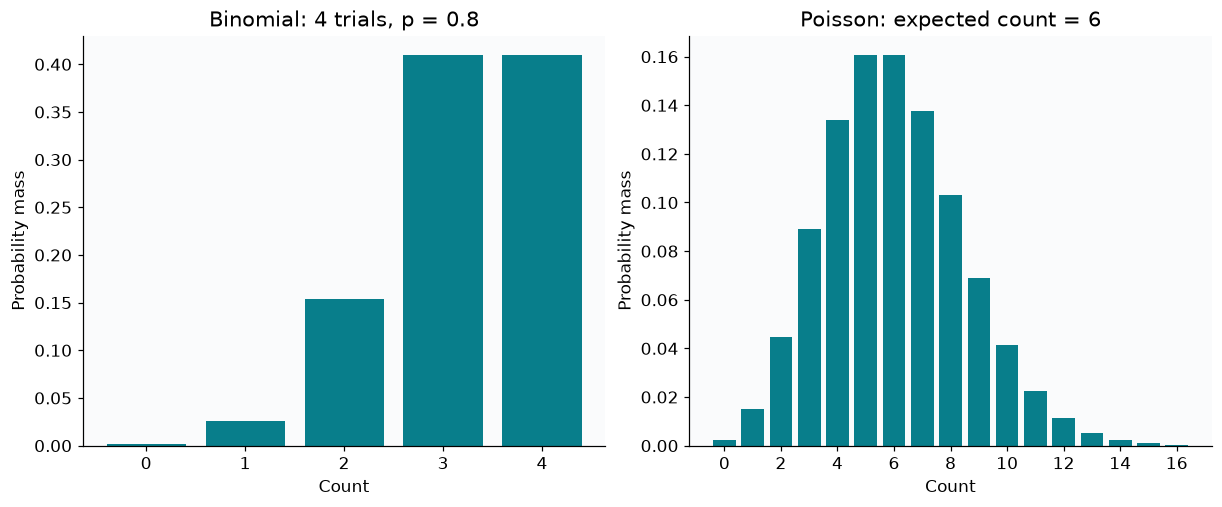

In [2]:
from math import comb
manual = comb(4,3) * .8**3 * .2
assert np.isclose(manual, stats.binom.pmf(3,4,.8))
print(f"P(K=3)={manual:.4f}; Poisson P(K=0)={stats.poisson.pmf(0,6):.6f}")
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
for ax, values, masses, title in [
    (axes[0], np.arange(5), stats.binom.pmf(np.arange(5),4,.8), "Binomial: 4 trials, p = 0.8"),
    (axes[1], np.arange(17), stats.poisson.pmf(np.arange(17),6), "Poisson: expected count = 6")]:
    ax.bar(values,masses,color=TEAL)
    ax.set(xlabel="Count",ylabel="Probability mass",title=title)
    ax.set_xticks(values[::1 if len(values)<=5 else 2])
save_figure(fig,"discrete_models")

## 4. Normal: a location and a spread

The normal distribution is

$$X\sim N(\mu,\sigma^2),\qquad
f(x)=\frac1{\sigma\sqrt{2\pi}}
\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right],\quad \sigma>0.$$

The mean $\mu$ sets its center. The SD $\sigma$ sets its width. A narrow curve must be taller to keep its total area equal to one. In this notation the second argument of $N(\mu,\sigma^2)$ is **variance**; SciPy's `scale` argument is **SD**.

Suppose a hypothetical sensor error is $N(0,2^2)$ millimeters. Then

$$P(-2\le X\le2)=\Phi(1)-\Phi(-1)\approx0.6827,$$

where $Z=(X-\mu)/\sigma$ has the standard normal distribution and $\Phi$ is its CDF. Approximately 68.27%, 95.45%, and 99.73% lie within one, two, and three SDs for a normal model. These percentages do not apply to every dataset with a mean and SD.

Under a continuous model, $P(X=0)=0$ even though $f(0)$ is the highest density. A recorded value of “0.0 mm” after rounding instead represents an interval such as $[-0.05,0.05)$; that interval has positive probability. A density value can exceed one and carries inverse measurement units.

## 5. Exponential and uniform: different shapes, different assumptions

If events follow a homogeneous Poisson process with rate $r$, the time $T$ until the next event is exponential:

$$f_T(t)=r e^{-rt}\quad(t\ge0),\qquad
P(T>t)=e^{-rt},\qquad E[T]=1/r.$$

At $r=0.25$ events per minute, mean waiting time is four minutes and $P(T>6)=e^{-1.5}\approx0.2231$. In SciPy use `expon(scale=1/r)`, not `scale=r`. The exponential distribution is memoryless: $P(T>s+t\mid T>s)=P(T>t)$. This assumption is unsuitable when an item wears out or a service schedule makes a long wait change the chance of imminent arrival.

A continuous uniform model on $[a,b]$ has density $1/(b-a)$ inside the interval and zero outside. Equal-length subintervals have equal probability. If a randomized delay is uniform between 2 and 6 seconds, $P(3\le X\le4.5)=1.5/4=0.375$. SciPy uses `uniform(loc=a, scale=b-a)`. Equal point probabilities are all zero; equality of interval probabilities is the useful statement.

![Continuous distributions with probability shown as area](figure/continuous_models.png)

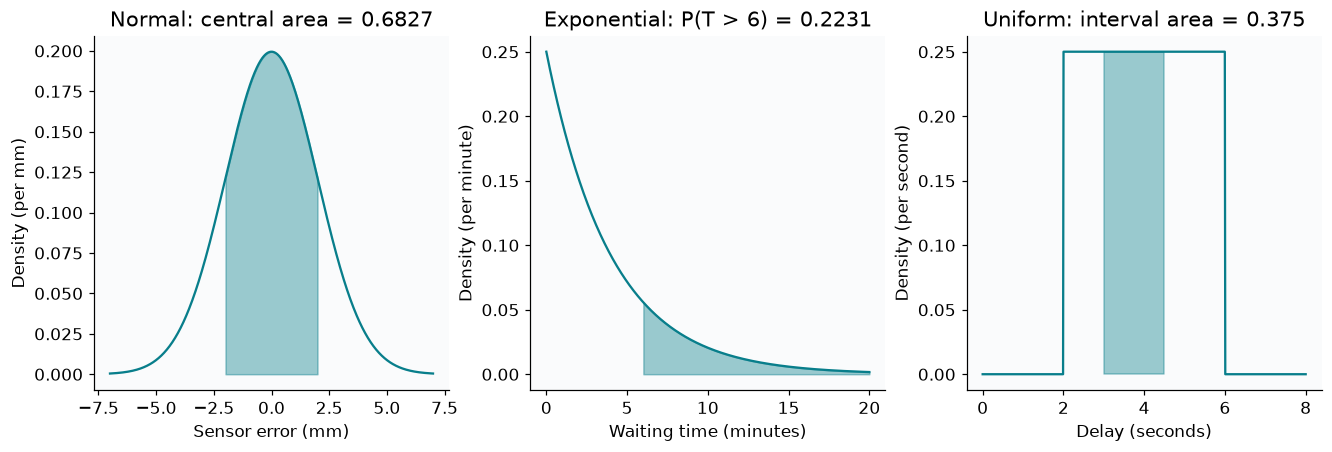

Normal central probability: 0.6826894921370859
P(recorded 0.0 mm): 0.019945036390476067


In [3]:
fig, axes = plt.subplots(1,3,figsize=(12,4),layout="constrained")
z = np.linspace(-7,7,700)
axes[0].plot(z,stats.norm.pdf(z,0,2))
axes[0].fill_between(z,stats.norm.pdf(z,0,2),where=(abs(z)<=2),color=TEAL,alpha=.4)
axes[0].set(title="Normal: central area = 0.6827",xlabel="Sensor error (mm)",ylabel="Density (per mm)")
t = np.linspace(0,20,700)
axes[1].plot(t,stats.expon.pdf(t,scale=4))
axes[1].fill_between(t,stats.expon.pdf(t,scale=4),where=t>6,color=TEAL,alpha=.4)
axes[1].set(title="Exponential: P(T > 6) = 0.2231",xlabel="Waiting time (minutes)",ylabel="Density (per minute)")
u = np.linspace(0,8,700)
axes[2].plot(u,stats.uniform.pdf(u,loc=2,scale=4))
axes[2].fill_between(u,stats.uniform.pdf(u,loc=2,scale=4),where=(u>=3)&(u<=4.5),color=TEAL,alpha=.4)
axes[2].set(title="Uniform: interval area = 0.375",xlabel="Delay (seconds)",ylabel="Density (per second)")
save_figure(fig,"continuous_models")
print("Normal central probability:",stats.norm.cdf(2,0,2)-stats.norm.cdf(-2,0,2))
print("P(recorded 0.0 mm):",stats.norm.cdf(.05,0,2)-stats.norm.cdf(-.05,0,2))

## 6. Beyond the five: other distributions you will meet

The five families above are a useful starting set, not a complete classification. The tables below list other common families, what each one models, and how to call it in SciPy. Read “Mean” as the expected value under the stated parameters.

**Discrete families**

| Model | Possible values | What it models | Parameters | Mean | SciPy |
|---|---|---|---|---|---|
| Bernoulli | $0,1$ | One trial with two outcomes, such as pass/fail | $p$: probability of success | $p$ | `bernoulli(p)` |
| Categorical | One of $k$ labels | One outcome from several categories, such as red, green, or blue | $p_1,\ldots,p_k$: category probabilities summing to 1 | $P(\text{category } j)=p_j$ | `multinomial(1, [p1, ..., pk])` |
| Multinomial | Counts $(x_1,\ldots,x_k)$ summing to $n$ | Counts across several categories after a fixed number of independent trials | $n$: trials; $p_1,\ldots,p_k$ | $E[X_j]=np_j$ | `multinomial(n, [p1, ..., pk])` |
| Geometric | $1,2,3,\ldots$ | Number of independent trials until the first success | $p$: success probability per trial | $1/p$ | `geom(p)` |
| Negative binomial | $0,1,2,\ldots$ | Number of failures before the $r$th success; also counts with more variation than Poisson | $r$: required successes; $p$: success probability | $r(1-p)/p$ | `nbinom(r, p)` |
| Hypergeometric | $0,\ldots,\min(n,M)$ | Number of marked items in $n$ draws **without replacement** | $N$: population size; $M$: marked items; $n$: draws | $nM/N$ | `hypergeom(M=N, n=M, N=n)` |
| Discrete uniform | Integers $a,\ldots,b$ | Equally probable integer outcomes, such as a fair die roll | $a,b$: smallest and largest integers | $(a+b)/2$ | `randint(a, b + 1)` |

**Continuous families**

| Model | Possible values | What it models | Parameters | Mean | SciPy |
|---|---|---|---|---|---|
| Beta | $0<x<1$ | Values between 0 and 1; often used to model an unknown probability | $\alpha,\beta>0$: shape parameters | $\alpha/(\alpha+\beta)$ | `beta(a, b)` |
| Gamma | $x>0$ | Positive quantities, including waiting time until several Poisson-process events | $\alpha>0$: shape; $\theta>0$: scale | $\alpha\theta$ | `gamma(a, scale=theta)` |
| Chi-squared | $x\ge0$ | Sum of squares of $\nu$ independent standard normal variables; used in variance and goodness-of-fit tests | $\nu$: degrees of freedom | $\nu$ | `chi2(nu)` |
| Student's $t$ | All real numbers | Symmetric variation with heavier tails than a normal; used in inference about means | $\nu$: degrees of freedom | $0$ for $\nu>1$ | `t(nu)` |
| $F$ | $x\ge0$ | Ratio of two independent chi-squared variables, each divided by its degrees of freedom; used to compare variances and models | $d_1,d_2$: numerator and denominator degrees of freedom | $d_2/(d_2-2)$ for $d_2>2$ | `f(d1, d2)` |
| Log-normal | $x>0$ | Positive quantities whose logarithms are normally distributed | $\mu,\sigma$: mean and SD of $\log X$ | $e^{\mu+\sigma^2/2}$ | `lognorm(s=sigma, scale=exp(mu))` |
| Weibull | $x\ge0$ | Lifetimes or failure times with different patterns of failure risk | $k>0$: shape; $\lambda>0$: scale | $\lambda\,\Gamma(1+1/k)$ | `weibull_min(c=k, scale=lam)` |

Here $\Gamma$ in the Weibull mean is the gamma function, which extends the factorial: $\Gamma(m)=(m-1)!$ for positive integers $m$. The Weibull shape $k$ describes how failure risk changes with age: $k<1$ means risk decreases (early failures), $k=1$ means constant risk, and $k>1$ means risk increases (wear-out).

**Watch the parameter conventions.** Textbooks and software name and order parameters differently:

- The geometric distribution can count **trials** until the first success (support $1,2,\ldots$; SciPy's `geom`) or **failures** before it (support $0,1,\ldots$). Their means differ by one.
- SciPy's `hypergeom(M, n, N)` uses $M$ for the population size, $n$ for the number of marked items, and $N$ for the number of draws. The table's $N,M,n$ follow the more common textbook letters, so the arguments look swapped.
- Gamma and exponential distributions are written with a **rate** $r$ or a **scale** $\theta=1/r$. SciPy uses scale.
- SciPy's log-normal uses `s` for $\sigma$ and `scale` for $e^{\mu}$.

**Useful relationships.** These connect the new families to the ones you already know:

- Bernoulli is a binomial distribution with $n=1$.
- Categorical is a multinomial distribution with $n=1$.
- The geometric distribution counts trials until the first success; the negative binomial with $r=1$ counts the failures before that success, so the two differ by one.
- Exponential is a gamma distribution with shape $\alpha=1$, and also a Weibull distribution with shape $k=1$.
- Chi-squared with $\nu$ degrees of freedom is a gamma distribution with shape $\nu/2$ and scale 2.
- Student's $t$ approaches the standard normal distribution as its degrees of freedom increase.
- The binomial distribution is the with-replacement counterpart of the hypergeometric; the two are close when the population is much larger than the number of draws.

![Typical shapes of fourteen additional probability distributions](figure/distribution_gallery.png)

**Read the plot:** teal bars are probability masses of discrete families; add them to obtain probabilities. Curves are densities of continuous families; probabilities are areas under them. Changing a parameter can change the shape completely: the Beta density can peak in the middle or pile up at both ends, and the Weibull density with $k=0.8$ decreases from zero while $k=2.5$ rises to a peak. In the Student's $t$ panel, the curve with $\nu=2$ has visibly heavier tails than the standard normal; with $\nu=10$, it is already close.

**Notebook experiment:** the code checks each relationship above numerically and compares each mean formula with SciPy. Change a parameter, predict how the shape and mean should move, and then rerun the cell.

In [4]:
from scipy.special import gamma as gamma_function

# Check the relationships listed in Section 6.
assert np.allclose(stats.bernoulli.pmf([0, 1], 0.3), stats.binom.pmf([0, 1], 1, 0.3))
assert np.allclose(stats.multinomial.pmf(np.eye(3), 1, [0.5, 0.3, 0.2]), [0.5, 0.3, 0.2])
failures = np.arange(0, 8)
# SciPy's geom counts trials (1, 2, ...); nbinom counts failures (0, 1, ...).
assert np.allclose(stats.geom.pmf(failures + 1, 0.4), stats.nbinom.pmf(failures, 1, 0.4))
t_grid = np.linspace(0.01, 12, 300)
assert np.allclose(stats.expon.pdf(t_grid, scale=2), stats.gamma.pdf(t_grid, a=1, scale=2))
assert np.allclose(stats.chi2.pdf(t_grid, 4), stats.gamma.pdf(t_grid, a=4/2, scale=2))
assert np.allclose(stats.weibull_min.pdf(t_grid, c=1, scale=2), stats.expon.pdf(t_grid, scale=2))
z = np.linspace(-4, 4, 161)
t_gap = {nu: np.abs(stats.t.pdf(z, nu) - stats.norm.pdf(z)).max() for nu in [2, 10, 100]}
assert t_gap[2] > t_gap[10] > t_gap[100]
print("Largest |t density - normal density|:", {nu: round(float(g), 4) for nu, g in t_gap.items()})

# Check the mean formulas with example parameter values.
catalog = {
    "Geometric(p=0.4), trials":            (stats.geom(0.4), 1/0.4),
    "Negative binomial(r=3, p=0.4)":       (stats.nbinom(3, 0.4), 3*0.6/0.4),
    "Hypergeometric(N=20, M=5, n=4)":      (stats.hypergeom(M=20, n=5, N=4), 4*5/20),
    "Discrete uniform(1, ..., 6)":         (stats.randint(1, 7), 3.5),
    "Beta(2, 5)":                          (stats.beta(2, 5), 2/7),
    "Gamma(shape 3, scale 2)":             (stats.gamma(a=3, scale=2), 6),
    "Chi-squared(4)":                      (stats.chi2(4), 4),
    "Student t(5)":                        (stats.t(5), 0),
    "F(5, 10)":                            (stats.f(5, 10), 10/8),
    "Log-normal(mu=0, sigma=0.5)":         (stats.lognorm(s=0.5, scale=np.exp(0)), np.exp(0.5**2/2)),
    "Weibull(k=2, lambda=3)":              (stats.weibull_min(c=2, scale=3), 3*gamma_function(1 + 1/2)),
}
table = pd.DataFrame({name: {"formula mean": formula, "SciPy mean": dist.mean(), "SciPy variance": dist.var()}
                      for name, (dist, formula) in catalog.items()}).T
assert np.allclose(table["formula mean"], table["SciPy mean"])
display(table.round(4))

# Gallery of the additional distributions.
fig, axes = plt.subplots(4, 4, figsize=(14, 12.5), layout="constrained")
axes = axes.ravel()
def stems(ax, x, p, title):
    ax.bar(x, p, width=0.7, color=TEAL)
    ax.set(title=title, ylabel="Probability")
def curves(ax, x, specs, title, loc="best"):
    for (y, label), color in zip(specs, [PURPLE, ORANGE, TEAL]):
        ax.plot(x, y, color=color, lw=2, label=label)
    ax.set(title=title, ylabel="Density")
    if len(specs) > 1:
        ax.legend(fontsize=8, frameon=False, loc=loc)

stems(axes[0], [0, 1], stats.bernoulli.pmf([0, 1], 0.3), "Bernoulli(p = 0.3)")
axes[0].set_xticks([0, 1], ["0: fail", "1: success"])
axes[1].bar(["red", "green", "blue"], [0.5, 0.3, 0.2], color=TEAL, width=0.7)
axes[1].set(title="Categorical(0.5, 0.3, 0.2)", ylabel="Probability")
grid = np.array([[stats.multinomial.pmf([a, b, 4 - a - b], 4, [0.5, 0.3, 0.2]) if a + b <= 4 else np.nan
                  for b in range(5)] for a in range(5)])
axes[2].imshow(grid, origin="lower", cmap="Blues")
axes[2].set(title="Multinomial(n=4; 0.5, 0.3, 0.2)", xlabel="count of green", ylabel="count of red")
for a in range(5):
    for b in range(5 - a):
        axes[2].text(b, a, f"{grid[a, b]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if grid[a, b] > 0.09 else "#1E293B")
k = np.arange(1, 13)
stems(axes[3], k, stats.geom.pmf(k, 0.4), "Geometric(p = 0.4): trials")
k = np.arange(0, 16)
stems(axes[4], k, stats.nbinom.pmf(k, 3, 0.4), "Neg. binomial(r=3, p=0.4): failures")
k = np.arange(0, 5)
stems(axes[5], k, stats.hypergeom.pmf(k, 20, 5, 4), "Hypergeometric(N=20, M=5, n=4)")
k = np.arange(1, 7)
stems(axes[6], k, stats.randint.pmf(k, 1, 7), "Discrete uniform(1, ..., 6)")
x01 = np.linspace(0.001, 0.999, 400)
curves(axes[7], x01, [(stats.beta.pdf(x01, 2, 5), "α=2, β=5"), (stats.beta.pdf(x01, 2, 2), "α=2, β=2"),
                      (stats.beta.pdf(x01, 0.5, 0.5), "α=β=0.5")], "Beta")
axes[7].set_ylim(0, 4)
xpos = np.linspace(0.001, 20, 500)
curves(axes[8], xpos, [(stats.gamma.pdf(xpos, a=1, scale=2), "shape 1 (exponential)"),
                       (stats.gamma.pdf(xpos, a=3, scale=2), "shape 3")], "Gamma (scale 2)")
curves(axes[9], xpos, [(stats.chi2.pdf(xpos, nu), f"ν = {nu}") for nu in [2, 4, 8]], "Chi-squared")
axes[9].set_ylim(0, 0.5)
zz = np.linspace(-5, 5, 400)
curves(axes[10], zz, [(stats.t.pdf(zz, 2), "t, ν = 2"), (stats.t.pdf(zz, 10), "t, ν = 10"),
                      (stats.norm.pdf(zz), "standard normal")], "Student's t", loc="upper left")
xf = np.linspace(0.001, 5, 400)
curves(axes[11], xf, [(stats.f.pdf(xf, 5, 10), "d1 = 5, d2 = 10"), (stats.f.pdf(xf, 2, 20), "d1 = 2, d2 = 20")], "F")
xl = np.linspace(0.001, 5, 400)
curves(axes[12], xl, [(stats.lognorm.pdf(xl, s=0.5), "μ = 0, σ = 0.5"), (stats.lognorm.pdf(xl, s=1), "μ = 0, σ = 1")],
       "Log-normal")
xw = np.linspace(0.001, 8, 400)
curves(axes[13], xw, [(stats.weibull_min.pdf(xw, c=0.8, scale=3), "k = 0.8"),
                      (stats.weibull_min.pdf(xw, c=1, scale=3), "k = 1 (exponential)"),
                      (stats.weibull_min.pdf(xw, c=2.5, scale=3), "k = 2.5")], "Weibull (λ = 3)")
axes[13].set_ylim(0, 0.6)
for ax in axes[14:]:
    ax.axis("off")
axes[14].text(0, 0.75, "Teal bars: discrete masses\n(add them for probabilities)\n\n"
              "Curves: continuous densities\n(probability = area under the curve)",
              fontsize=11, va="top", transform=axes[14].transAxes)
fig.suptitle("Additional probability distributions: typical shapes", fontsize=16)
save_figure(fig, "distribution_gallery")

Largest |t density - normal density|: {2: 0.0578, 10: 0.0132, 100: 0.0014}


,formula mean,SciPy mean,SciPy variance
"Geometric(p=0.4), trials",2.5000,2.5000,3.7500
"Negative binomial(r=3, p=0.4)",4.5000,4.5000,11.2500
"Hypergeometric(N=20, M=5, n=4)",1.0000,1.0000,0.6316
"Discrete uniform(1, ..., 6)",3.5000,3.5000,2.9167
"Beta(2, 5)",0.2857,0.2857,0.0255
"Gamma(shape 3, scale 2)",6.0000,6.0000,12.0000
Chi-squared(4),4.0000,4.0000,8.0000
Student t(5),0.0000,0.0000,1.6667
"F(5, 10)",1.2500,1.2500,1.3542
"Log-normal(mu=0, sigma=0.5)",1.1331,1.1331,0.3647


<Figure size 1540x1375 with 16 Axes>

## 7. Probability versus likelihood: what is held fixed?

Probability and likelihood use the **same formula**, $f(x\mid\theta)$, but read it in opposite directions. A **probability** calculation holds the model parameter $\theta$ fixed and asks about possible data. A **likelihood** holds the observed data fixed and compares candidate parameter values.

| | Probability | Likelihood |
|---|---|---|
| Held fixed | Parameter $\theta$ | Observed data $x_1,\ldots,x_n$ |
| Allowed to vary | Possible data values | Candidate parameter values |
| Question | “If $\theta$ were true, how likely are these outcomes?” | “Given these data, how well does each $\theta$ explain them?” |
| Totals one over | All possible data | Not required over $\theta$ |

**Definition.** For independent observations, the **likelihood** of $\theta$ is the product of the density (or, for discrete data, mass) values at the observations. The **log likelihood** is its natural logarithm:

$$L(\theta;x_1,\ldots,x_n)=\prod_{i=1}^n f(x_i\mid\theta),\qquad
\ell(\theta)=\ln L(\theta)=\sum_{i=1}^n\ln f(x_i\mid\theta).$$

In statistics, “log” without a base means the **natural logarithm** $\ln$, with base $e\approx2.718$. NumPy follows the same convention: `np.log` is $\ln$, and `np.log10` is base 10.

### Step by step: two observations

Suppose a model with parameter $\theta$ gives two independent observations density heights of 0.5 and 0.25 under a candidate value $\theta_A$, and 0.4 and 0.1 under another candidate $\theta_B$.

1. **Read the height at each observation.** Each height says how typical that observation is under the candidate. A height is not a probability; it has units of “per unit of $x$” and can exceed one.
2. **Multiply the heights.** The data consist of observation 1 **and** observation 2. For independent observations, “and” means multiplication, just as $P(A\cap B)=P(A)P(B)$ for independent events:

   $$L(\theta_A)=0.5\times0.25=0.125,\qquad L(\theta_B)=0.4\times0.1=0.04.$$

3. **Take the natural log.** Because $\ln(ab)=\ln a+\ln b$, the product becomes a sum of logs:

   $$\ell(\theta_A)=\ln0.5+\ln0.25=-0.69315-1.38629=-2.07944,$$
   $$\ell(\theta_B)=\ln0.4+\ln0.1=-0.91629-2.30259=-3.21888.$$

   Negative values are normal: the log of any number between 0 and 1 is negative. A log likelihood is not a probability.

4. **Compare candidates on the same data.** $\theta_A$ explains the data better. The likelihood ratio is $L(\theta_A)/L(\theta_B)=0.125/0.04=3.125$, and the log-likelihood difference is $-2.07944-(-3.21888)=1.13943=\ln3.125$. A single likelihood value, such as 0.125, has no meaning on its own; comparisons between candidates do.

**Why multiply instead of add?** Addition is for “A **or** B” with mutually exclusive outcomes; here both observations occur together. A sum also fails to detect a poor fit. Add a third observation with height 0.001 under $\theta_A$, an observation the candidate explains very badly. The product falls from 0.125 to 0.000125, a thousandfold drop that correctly flags the misfit. The sum barely moves, from 0.75 to 0.751. **A sum of density heights is not the joint likelihood.**

**Why take logs?** First, numerical safety: multiplying 1,000 densities smaller than one can produce a number too small for a computer to store, which rounds to zero (**underflow**). Adding 1,000 logs avoids that. Second, simpler algebra: logs turn products into sums and cancel the exponentials in densities such as the normal. Because $\ln$ is increasing, the parameter that maximizes $\ell$ also maximizes $L$.

**Does the base matter?** Not for which candidate wins. Changing the base multiplies every log likelihood by the same positive constant: $\log_{10}L=\ln L/\ln10=\ln L/2.302585$. For $\theta_A$, $\ln0.125=-2.07944$ while $\log_{10}0.125=-0.90309$; the ranking of candidates is unchanged. Use $\ln$, because derivatives, likelihood-ratio tests, AIC, and BIC are all defined with natural logs.

### Worked example: which mean best explains three readings?

Three invented sensor readings are $x=(9,10,14)$, modeled as independent $N(\mu,2^2)$ with known $\sigma=2$. The data stay fixed; we move the candidate mean $\mu$. Each height is

$$f(x_i\mid\mu)=\frac{1}{2\sqrt{2\pi}}\exp\!\left[-\frac{(x_i-\mu)^2}{8}\right],\qquad \frac{1}{2\sqrt{2\pi}}\approx0.19947.$$

| Candidate $\mu$ | $f(9\mid\mu)$ | $f(10\mid\mu)$ | $f(14\mid\mu)$ | Likelihood $L(\mu)$ | Log likelihood $\ell(\mu)$ | Sum of heights |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 0.17603 | 0.19947 | 0.02700 | 0.000948 | $-6.9613$ | 0.4025 |
| 11 | 0.12099 | 0.17603 | 0.06476 | 0.001379 | $-6.5863$ | 0.3618 |

![Two normal curves with means 10 and 11, showing the density height at each of the three readings](figure/likelihood_heights.png)

**Read the plot:** the three readings, marked on the horizontal axis, are identical in both panels; only the curve moves. With $\mu=10$, readings 9 and 10 sit near the peak, but 14 sits far out in the tail, with height 0.027. With $\mu=11$, the first two heights shrink slightly while the height at 14 more than doubles. Multiplying the heights rewards the candidate that explains **all** observations reasonably, so $\mu=11$ wins: $L(11)/L(10)=0.001379/0.000948\approx1.455$. The sum of heights would wrongly favor $\mu=10$ (0.4025 versus 0.3618), because adding lets two well-fitted points hide one badly fitted point.

**Find the best $\mu$ algebraically.** Taking $\ln$ of the product gives

$$\ell(\mu)=-3\ln(2\sqrt{2\pi})-\frac{(9-\mu)^2+(10-\mu)^2+(14-\mu)^2}{8}.$$

The first term does not depend on $\mu$. Maximizing $\ell$ therefore means minimizing the sum of squared distances $(9-\mu)^2+(10-\mu)^2+(14-\mu)^2$. Setting its derivative to zero, $-2[(9-\mu)+(10-\mu)+(14-\mu)]=0$, gives $\hat\mu=\bar x=33/3=11$. At $\mu=11$ the squared distances sum to $4+1+9=14$; at $\mu=10$ they sum to $1+0+16=17$. Hence

$$\ell(11)-\ell(10)=\frac{17-14}{8}=\frac38=0.375,\qquad \frac{L(11)}{L(10)}=e^{3/8}\approx1.455,$$

matching the table.

![Likelihood for the same readings under candidate means](figure/likelihood.png)

**Read the plot:** each point on the curve repeats the table calculation for one candidate mean. The curve peaks at the **maximum likelihood estimate (MLE)**, $\hat\mu=11$, and falls on both sides. The vertical axis subtracts the maximum, so the peak is at zero and the curve shows how much worse each other candidate explains the same data.

**What the MLE is not.** The MLE is the allowed parameter value that maximizes the likelihood. A likelihood is not the probability that a parameter is true: it is a function of $\theta$ that need not integrate to one over parameter values. Turning it into probabilities for parameters requires a prior distribution and normalization, as in Bayesian analysis.

**A note on variance.** When both parameters of an iid normal model are unknown, the MLE of the variance divides the sum of squared deviations by $n$, whereas the unbiased estimator from Chapter 1 divides by $n-1$. They answer different criteria, maximum likelihood versus correct on average, so there is no contradiction.

In [5]:
readings = np.array([9,10,14])
mu_grid = np.linspace(6,17,1101)
log_likelihood = stats.norm.logpdf(readings[:,None],loc=mu_grid,scale=2).sum(axis=0)
mu_hat = mu_grid[log_likelihood.argmax()]
assert np.isclose(mu_hat,11)
ll_at_11 = stats.norm.logpdf(readings,loc=11,scale=2).sum()
ll_at_10 = stats.norm.logpdf(readings,loc=10,scale=2).sum()
assert np.isclose(ll_at_11-ll_at_10,3/8)
fig, ax = plt.subplots(layout="constrained")
ax.plot(mu_grid,log_likelihood-log_likelihood.max(),label="Log likelihood minus its maximum")
ax.axvline(readings.mean(),ls="--",color=ORANGE,label="MLE = sample mean = 11")
ax.set(xlabel="Candidate mean (sensor units)",ylabel="Relative log likelihood",title="Keep the data fixed; vary the model's mean")
ax.legend()
save_figure(fig,"likelihood")
print("Likelihood ratio L(11)/L(10):",np.exp(ll_at_11-ll_at_10))
print("Normal variance MLE:",readings.var(ddof=0),"; unbiased estimate:",readings.var(ddof=1))
# Section 7 step-by-step example: multiply heights, then take natural logs.
heights_A, heights_B = np.array([0.5, 0.25]), np.array([0.4, 0.1])
assert np.isclose(heights_A.prod(), 0.125) and np.isclose(heights_B.prod(), 0.04)
assert np.isclose(np.log(heights_A).sum(), np.log(0.125))
assert np.isclose(np.log(heights_A).sum() - np.log(heights_B).sum(), np.log(3.125))
assert np.isclose(np.log10(0.125), np.log(0.125) / np.log(10))
with_bad_point = np.r_[heights_A, 0.001]
print("Product with a badly fitted third point:", with_bad_point.prod(), "| sum:", with_bad_point.sum())

# Density heights at two candidate means: the readings stay fixed, the curve moves.
heights_at = {mu: stats.norm.pdf(readings, loc=mu, scale=2) for mu in [10, 11]}
assert np.isclose(heights_at[11].prod() / heights_at[10].prod(), np.exp(3/8))
assert heights_at[10].sum() > heights_at[11].sum()  # the sum would pick the wrong mean
display(pd.DataFrame({mu: {**{f"f({x}|mu)": h for x, h in zip(readings, hs)},
                           "likelihood": hs.prod(), "log likelihood": np.log(hs).sum(),
                           "sum of heights": hs.sum()} for mu, hs in heights_at.items()}).T.round(6))
x_grid = np.linspace(2, 20, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
for ax, (mu, hs), color in zip(axes, heights_at.items(), [ORANGE, TEAL]):
    ax.plot(x_grid, stats.norm.pdf(x_grid, mu, 2), color=color, lw=2.2, label=f"N({mu}, 2²) density")
    ax.vlines(readings, 0, hs, color=PURPLE, lw=2.2)
    ax.plot(readings, hs, "o", color=PURPLE, ms=7, label="height at each reading")
    ax.plot(readings, np.zeros(3), "|", color="#334155", ms=16, mew=2)
    for x, h in zip(readings, hs):
        left = x == readings.min()  # keep the label for 9 clear of the stem at 10
        ax.text(x - 0.25 if left else x + 0.25, h + 0.004, f"{h:.4f}", ha="right" if left else "left",
                va="bottom", fontsize=10, color=PURPLE,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
    ax.text(0.02, 0.97, f"L = product = {hs.prod():.6f}\nℓ = ln L = {np.log(hs).sum():.4f}\n"
            f"sum of heights = {hs.sum():.4f} (not L)", transform=ax.transAxes, va="top", fontsize=10)
    ax.set(title=f"Candidate mean μ = {mu}", xlabel="Sensor reading", ylim=(0, 0.26), xlim=(2, 20))
    ax.legend(loc="upper right", fontsize=9, frameon=False)
axes[0].set_ylabel("Density f(x | μ, σ = 2)")
fig.suptitle("Same three readings, two candidate means: the likelihood multiplies the heights", fontsize=14)
save_figure(fig, "likelihood_heights")

<Figure size 990x528 with 1 Axes>

Likelihood ratio L(11)/L(10): 1.4549914146182013
Normal variance MLE: 4.666666666666667 ; unbiased estimate: 7.0
Product with a badly fitted third point: 0.000125 | sum: 0.751


,f(9|mu),f(10|mu),f(14|mu),likelihood,log likelihood,sum of heights
10,0.176033,0.199471,0.026995,0.000948,-6.961257,0.402499
11,0.120985,0.176033,0.064759,0.001379,-6.586257,0.361777


<Figure size 1320x528 with 2 Axes>

## 8. Model checking and limits

First check support: a normal model gives some probability to negative values, so it can be poor for waiting times near zero. Next compare simulated observations to the observed shape, including tails and variation. Check whether mean and variance agree approximately with a proposed Poisson model. Consider how data were generated rather than selecting a distribution solely because a histogram resembles a familiar curve.

Estimating parameters and treating them as known understates predictive uncertainty. A model fitted to a tiny sample can make precise-looking predictions that have little evidential support. Validation, sensitivity to alternative models, and interval estimates help expose that uncertainty.

## 9. Practice

1. For six independent trials with $p=0.3$, calculate $P(K=2)$ and $P(K\ge1)$.
2. An idealized Poisson counter records 3 events per hour. What parameter applies to a two-hour window, and what is the probability of zero events?
3. If a thickness is modeled as $N(12,1.5^2)$ mm, calculate $P(10.5\le X\le15)$.
4. A uniform density spans 0 to 0.2 seconds. What is its height, and what is $P(X<0.05)$?
5. Independent observations have densities 0.2 and 0.4 at a candidate parameter. What is their joint likelihood? What is the log likelihood?

## 10. Worked answers

1. $\binom62(0.3)^2(0.7)^4=0.324135$; $1-P(K=0)=1-0.7^6=0.882351$.
2. $\lambda=3\times2=6$; $P(K=0)=e^{-6}\approx0.002479$.
3. The standardized boundaries are $-1$ and $2$, so $\Phi(2)-\Phi(-1)\approx0.81859$.
4. Height is $1/0.2=5$ per second, and the requested area is $5(0.05)=0.25$.
5. $L=0.2\times0.4=0.08$ and $\ell=\log(0.08)\approx-2.52573$. The sum 0.6 is not their joint likelihood.

In [6]:
answers = {"binomial_exactly_two":stats.binom.pmf(2,6,.3),
           "binomial_at_least_one":stats.binom.sf(0,6,.3),
           "poisson_zero":stats.poisson.pmf(0,6),
           "normal_interval":stats.norm.cdf(15,12,1.5)-stats.norm.cdf(10.5,12,1.5),
           "likelihood":.2*.4,"log_likelihood":np.log(.2)+np.log(.4)}
display(pd.Series(answers,name="Answer"))
assert np.isclose(answers["binomial_exactly_two"],.324135)

binomial_exactly_two     0.324135
binomial_at_least_one    0.882351
poisson_zero             0.002479
normal_interval          0.818595
likelihood               0.080000
log_likelihood          -2.525729
Name: Answer, dtype: float64

## References and next step

Reading connection: Starmer (2026), Chapter 3, [SQ](../Reference.md#sq-statquest). The joint-likelihood convention follows [NIST maximum likelihood](https://www.itl.nist.gov/div898/handbook/apr/section4/apr412.htm). Computational definitions: [SciPy statistical distributions](https://docs.scipy.org/doc/scipy/reference/stats.html). Additional families: [NIST gallery of distributions](https://www.itl.nist.gov/div898/handbook/eda/section3/eda366.htm). Examples and parameter comparisons are original.

Next: [04 · Hypothesis testing](../04_Hypothesis_Testing/04_Hypothesis_Testing.md).